# Ejercicio k-Nearest Neighbor

## App Reviews
En este ejercicio vas a trabajar con una base de datos de reviews de una aplicación. Entre los datos podemos encontrar el texto de la review, las estrellas, así como el sentimiento del comentario (si es algo bueno o malo).

El objetivo es montar un algoritmo de clasificación que prediga el rating, en función del sentimiento del comentario y la cantidad de palabras empleadas en el mismo. Para ello tendrás que utilizar un algoritmo de tipo KNN.

## Importamos las librerías que vamos a utilizar

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Leemos nuestro archivo de entrada `reviews_sentiment`

Para facilitar el ejercicio, las columnas que utilizaremos serán: wordcount con la cantidad de palabras utilizadas y sentimentValue con un valor entre -4 y 4 que indica si el comentario fue valorado como positivo o negativo

Nuestras etiquetas, serán las estrellas que dieron los usuarios a la app, que son valores discretos del 1 al 5

In [9]:
df = pd.read_csv('./data/reviews_sentiment.csv', sep=';')
df.head()

,Review Title,Review Text,wordcount,titleSentiment,textSentiment,Star Rating,sentimentValue
0,Sin conexión,Hola desde hace algo más de un mes me pone sin...,23,negative,negative,1,-0.486389
1,faltan cosas,Han mejorado la apariencia pero no,20,negative,negative,1,-0.586187
2,Es muy buena lo recomiendo,Andres e puto amoooo,4,NaN,negative,1,-0.602240
3,Version antigua,Me gustana mas la version anterior esta es mas...,17,NaN,negative,1,-0.616271
4,Esta bien,Sin ser la biblia.... Esta bien,6,negative,negative,1,-0.651784


## Rápidas visualizaciones y análisis
Al menos realiza un análisis univariante y representa la distribución del rating. Realiza otras visualizaciones para ver la relación de tus datos.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257 entries, 0 to 256
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    257 non-null    object 
 1   Review Text     257 non-null    object 
 2   wordcount       257 non-null    int64  
 3   titleSentiment  231 non-null    object 
 4   textSentiment   257 non-null    object 
 5   Star Rating     257 non-null    int64  
 6   sentimentValue  257 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 14.2+ KB
None


,wordcount,Star Rating,sentimentValue
count,257.000000,257.000000,257.000000
mean,11.501946,3.420233,0.383849
std,13.159812,1.409531,0.897987
min,1.000000,1.000000,-2.276469
25%,3.000000,3.000000,-0.108144
50%,7.000000,3.000000,0.264091
75%,16.000000,5.000000,0.808384
max,103.000000,5.000000,3.264579


C:\Users\laras\AppData\Local\Temp\ipykernel_20868\1417523332.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Star Rating', ax=axes[0], palette='viridis')


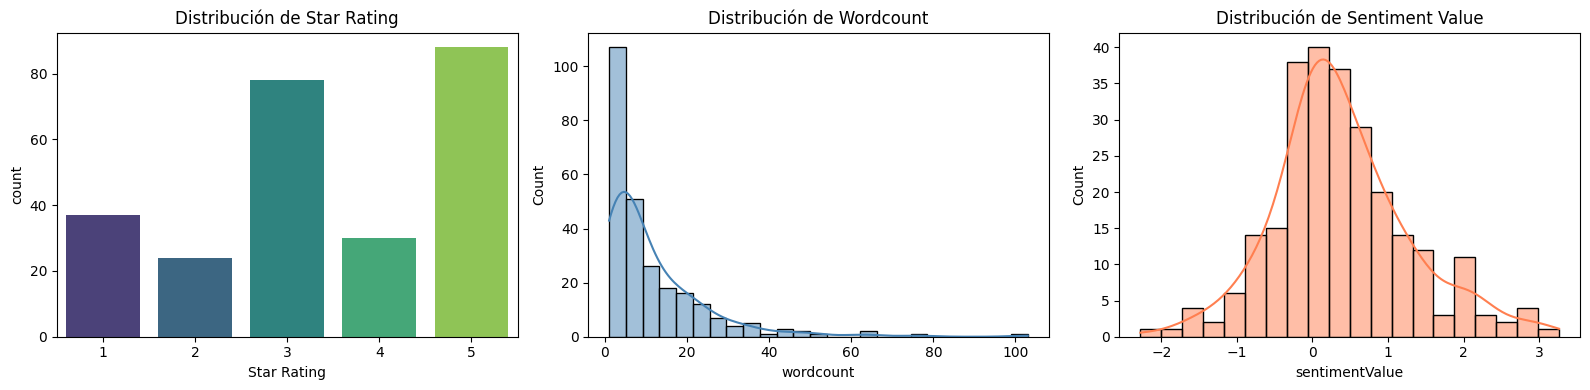

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Distribución del Star Rating (target)
sns.countplot(data=df, x='Star Rating', ax=axes[0], palette='viridis')
axes[0].set_title('Distribución de Star Rating')

# Distribución de wordcount
sns.histplot(data=df, x='wordcount', kde=True, ax=axes[1], color='steelblue')
axes[1].set_title('Distribución de Wordcount')

# Distribución de sentimentValue
sns.histplot(data=df, x='sentimentValue', kde=True, ax=axes[2], color='coral')
axes[2].set_title('Distribución de Sentiment Value')

plt.tight_layout()
plt.show()

In [12]:
df = df.dropna(subset=['titleSentiment']).reset_index(drop=True)

# Comprueba que ya no quedan nulos
df.isnull().sum()

Review Title      0
Review Text       0
wordcount         0
titleSentiment    0
textSentiment     0
Star Rating       0
sentimentValue    0
dtype: int64

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 231 entries, 0 to 230
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Review Title    231 non-null    object 
 1   Review Text     231 non-null    object 
 2   wordcount       231 non-null    int64  
 3   titleSentiment  231 non-null    object 
 4   textSentiment   231 non-null    object 
 5   Star Rating     231 non-null    int64  
 6   sentimentValue  231 non-null    float64
dtypes: float64(1), int64(2), object(4)
memory usage: 12.8+ KB


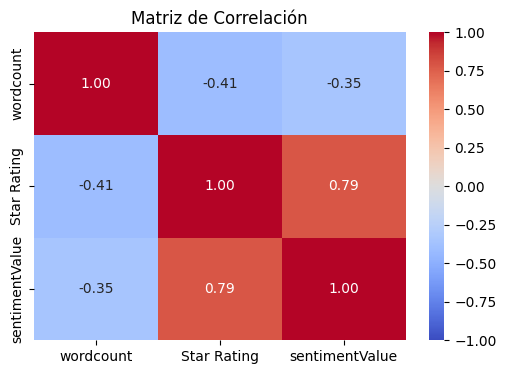

C:\Users\laras\AppData\Local\Temp\ipykernel_20868\3254665989.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Star Rating', y='sentimentValue', ax=axes[0], palette='viridis')
C:\Users\laras\AppData\Local\Temp\ipykernel_20868\3254665989.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Star Rating', y='wordcount', ax=axes[1], palette='viridis')


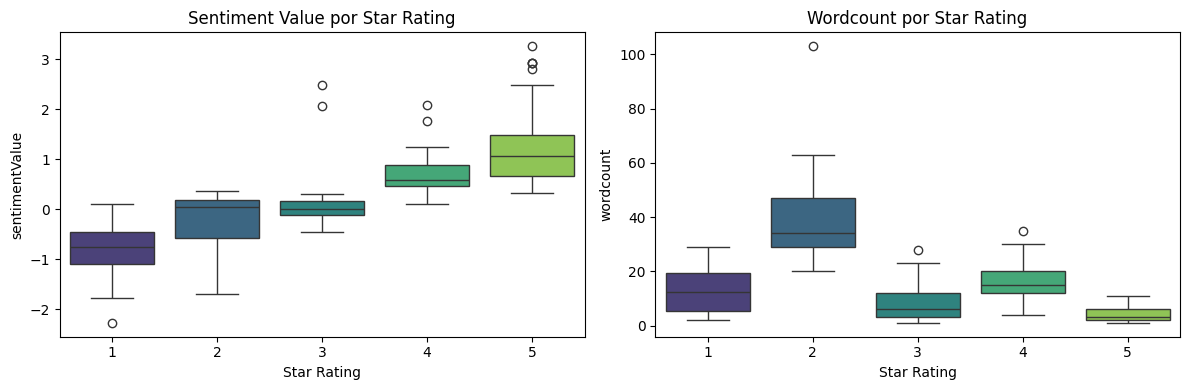

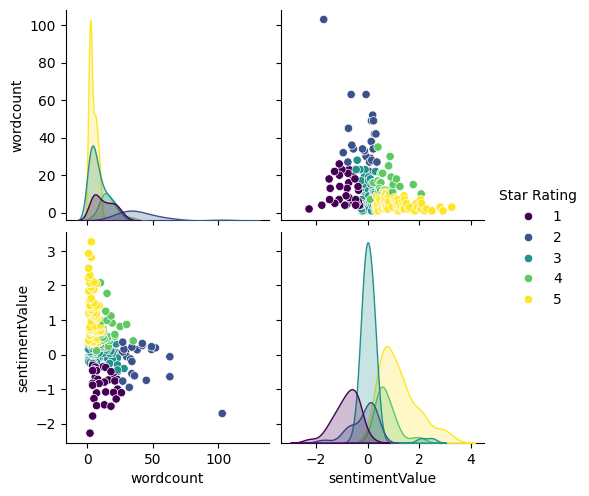

In [14]:
# 1. Matriz de correlación (solo columnas numéricas)
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de Correlación')
plt.show()

# 2. Relación de sentimentValue y wordcount frente a Star Rating
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x='Star Rating', y='sentimentValue', ax=axes[0], palette='viridis')
axes[0].set_title('Sentiment Value por Star Rating')

sns.boxplot(data=df, x='Star Rating', y='wordcount', ax=axes[1], palette='viridis')
axes[1].set_title('Wordcount por Star Rating')

plt.tight_layout()
plt.show()

# 3. Pairplot para ver la separación de clases (muy útil si luego aplicas KNN)
sns.pairplot(df[['wordcount', 'sentimentValue', 'Star Rating']], hue='Star Rating', palette='viridis')
plt.show()

In [15]:
#esta bien para knn porque los colores no se mezclan mucho


## Preparamos el dataset
Divide en train/test y escala las features en el rango [0, 1].

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 1. Separar features (X) y target (y)
X = df[['wordcount', 'sentimentValue']]
y = df['Star Rating']

# 2. Dividir en train y test (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Escalar las features en el rango [0, 1]
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Creamos el Modelo
Entrena con un KNN y evalúa el error en train y en test

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Instanciar y entrenar el modelo (k=5 vecinos por defecto)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# 2. Predecir sobre train y test (siempre con los datos escalados)
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

# 3. Calcular Accuracy y tasa de error (1 - Accuracy)
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Train Accuracy: {train_acc:.4f} | Train Error: {1 - train_acc:.4f}")
print(f"Test Accuracy:  {test_acc:.4f} | Test Error:  {1 - test_acc:.4f}")

# 4. Detalle de aciertos y errores por cada clase (1 a 5 estrellas) en test
print("\nReporte de clasificación (Test):")
print(classification_report(y_test, y_test_pred))

Train Accuracy: 0.9130 | Train Error: 0.0870
Test Accuracy:  0.8511 | Test Error:  0.1489

Reporte de clasificación (Test):
              precision    recall  f1-score   support

           1       0.86      1.00      0.92         6
           2       0.86      1.00      0.92         6
           3       0.77      0.83      0.80        12
           4       1.00      0.40      0.57         5
           5       0.89      0.89      0.89        18

    accuracy                           0.85        47
   macro avg       0.87      0.82      0.82        47
weighted avg       0.86      0.85      0.84        47



## Evalúa tu modelo

--- MÉTRICAS GLOBALES ---
Train Accuracy: 0.9130
Test Accuracy:  0.8511
Test Precision: 0.8621
Test Recall:    0.8511
Test F1-Score:  0.8412

--- REPORTE DE CLASIFICACIÓN (TEST) ---
              precision    recall  f1-score   support

           1       0.86      1.00      0.92         6
           2       0.86      1.00      0.92         6
           3       0.77      0.83      0.80        12
           4       1.00      0.40      0.57         5
           5       0.89      0.89      0.89        18

    accuracy                           0.85        47
   macro avg       0.87      0.82      0.82        47
weighted avg       0.86      0.85      0.84        47



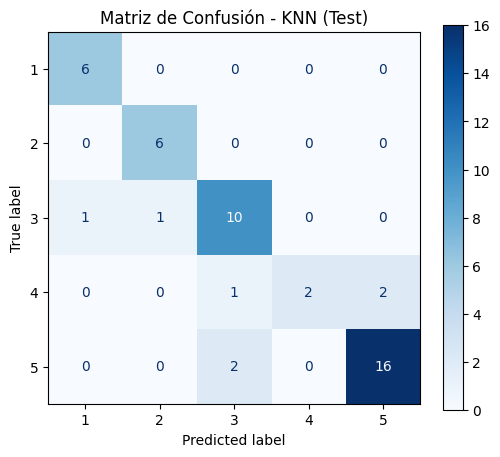

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Generar predicciones en train y test
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

# 2. Comparativa global Train vs. Test (para detectar overfitting)
print("--- MÉTRICAS GLOBALES ---")
print(f"Train Accuracy: {accuracy_score(y_train, y_train_pred):.4f}")
print(f"Test Accuracy:  {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Test Precision: {precision_score(y_test, y_test_pred, average='weighted'):.4f}")
print(f"Test Recall:    {recall_score(y_test, y_test_pred, average='weighted'):.4f}")
print(f"Test F1-Score:  {f1_score(y_test, y_test_pred, average='weighted'):.4f}")

# 3. Desglose detallado por cada clase (1 a 5 estrellas)
print("\n--- REPORTE DE CLASIFICACIÓN (TEST) ---")
print(classification_report(y_test, y_test_pred))

# 4. Matriz de confusión visual
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_test_pred, labels=knn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=knn.classes_)
disp.plot(cmap='Blues', ax=ax)
plt.title('Matriz de Confusión - KNN (Test)')
plt.show()

## ¿Cómo obtener el mejor valor de k? Crea y evalúa nuevos modelos
¿Qué valor de k maximiza el accuracy? Representa todas las iteraciones en un scatterplot -> k vs accuracy

El valor de k que maximiza el accuracy es k = 3 (Accuracy: 0.8511)


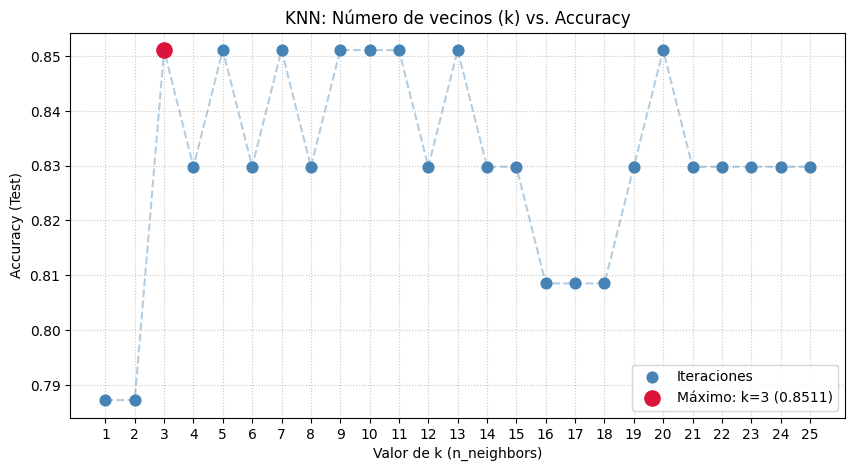

In [19]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

# 1. Probar distintos valores de k (del 1 al 25)
k_range = range(1, 26)
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred))

# 2. Obtener el k que maximiza el accuracy
best_idx = np.argmax(accuracies)
best_k = k_range[best_idx]
best_acc = accuracies[best_idx]

print(
    f"El valor de k que maximiza el accuracy es k = {best_k} (Accuracy:"
    f" {best_acc:.4f})"
)

# 3. Representar k vs accuracy en un scatterplot
plt.figure(figsize=(10, 5))
plt.scatter(
    k_range, accuracies, color="steelblue", s=60, zorder=3, label="Iteraciones"
)
plt.plot(
    k_range, accuracies, color="steelblue", linestyle="--", alpha=0.4
)  # Línea guía

# Resaltar el punto máximo en rojo
plt.scatter(
    best_k,
    best_acc,
    color="crimson",
    s=120,
    zorder=4,
    label=f"Máximo: k={best_k} ({best_acc:.4f})",
)

plt.title("KNN: Número de vecinos (k) vs. Accuracy")
plt.xlabel("Valor de k (n_neighbors)")
plt.ylabel("Accuracy (Test)")
plt.xticks(k_range)
plt.grid(True, linestyle=":", alpha=0.7)
plt.legend()
plt.show()

## Predice con nuevos datos.
Ejemplo: supongamos que nos llega una review de 5 palabras y sentimiento 1

In [20]:
import pandas as pd

# 0. Asegúrate de entrenar el modelo definitivo con el best_k obtenido antes
# (si no, la variable 'knn' del bucle anterior se habrá quedado con k=25)
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_scaled, y_train)

# 1. Crear el nuevo dato respetando el mismo nombre y orden de columnas que X_train
nueva_review = pd.DataFrame({
    'wordcount': [5],
    'sentimentValue': [1]
})

# 2. Escalar el dato nuevo con el MISMO scaler ajustado en train (solo .transform)
nueva_review_scaled = scaler.transform(nueva_review)

# 3. Predecir el rating y ver la votación de los vecinos
prediccion = knn_final.predict(nueva_review_scaled)
probabilidades = knn_final.predict_proba(nueva_review_scaled)

print(f"Predicción de Star Rating: {prediccion[0]} estrellas")
for clase, prob in zip(knn_final.classes_, probabilidades[0]):
    print(f"  {clase} estrella(s): {prob:.2%}")

Predicción de Star Rating: 5 estrellas
  1 estrella(s): 0.00%
  2 estrella(s): 0.00%
  3 estrella(s): 0.00%
  4 estrella(s): 0.00%
  5 estrella(s): 100.00%
